## Sentiment Analysis 

# <font color='#ff6ca4' size=5>1. Introduction</font> <a class="anchor" id="intro"></a>


Moving beyond genre classification, this notebook analyzes lyric sentiments to map emotional landscapes across musical genres. We examine core questions regarding predominant sentiments, temporal shifts, and song popularity. VADER provides lexicon-based polarity scores for a reproducible, genre-stratified 2% sample of the lyrics; scores are exploratory estimates, not human-labelled ground truth.

# <font color='#ff6ca4' size=5>2. Preparation</font> <a class="anchor" id="intro"></a>

Import datasets and libraries 

In [1]:
import pandas as pd 

df_train = pd.read_csv('data/train.csv')

/Users/joanaanmartins/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/joanaanmartins/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


# <font color='#ff6ca4' size=5>3. Data Exploration</font> <a class="anchor" id="intro"></a>

In [2]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# VADER is a lexicon baseline, not human-labelled ground truth.
sentiment_analyzer = SentimentIntensityAnalyzer()
df_sentiment = df_train.groupby('tag', group_keys=False).sample(frac=0.02, random_state=42).copy()
df_sentiment['lyrics'] = df_sentiment['lyrics'].fillna('').astype(str)
# Cap the text scored per lyric to keep this lexicon baseline practical.
scoring_text = df_sentiment['lyrics'].str.slice(0, 3000)
df_sentiment['sentiment_compound'] = scoring_text.map(
    lambda text: sentiment_analyzer.polarity_scores(text)['compound']
)
df_sentiment['sentiment'] = np.select(
    [df_sentiment['sentiment_compound'] <= -0.05,
     df_sentiment['sentiment_compound'] >= 0.05],
    ['Negative', 'Positive'],
    default='Neutral',
)
df_sentiment['lyric_word_count'] = df_sentiment['lyrics'].str.split().str.len()

print(f'Scored {len(df_sentiment):,} of {len(df_train):,} songs using a stratified 2% sample.')

Scored 2,700 of 134,967 songs using a stratified 2% sample.


### 3.1. General Exploration

#### 3.1.1. Shape and data types

In [6]:
print(df_train.shape)
print(df_train.dtypes)

(134967, 8)
title       object
tag         object
artist      object
year         int64
views        int64
features    object
lyrics      object
id           int64
dtype: object


#### 3.1.2. Missing Values 

In [7]:
print('Missing values by column:')
print(df_train.isna().sum())
print('\nBlank lyric texts:', df_train['lyrics'].fillna('').str.strip().eq('').sum())

Missing values by column:
title       2
tag         0
artist      0
year        0
views       0
features    0
lyrics      0
id          0
dtype: int64

Blank lyric texts: 0


#### 3.1.3. Duplicates

In [8]:
lyric_groups = df_train.groupby('lyrics', dropna=False).agg(
    row_count=('id', 'size'),
    genre_count=('tag', 'nunique'),
)
duplicate_groups = lyric_groups[lyric_groups['row_count'] > 1]
conflicting_groups = duplicate_groups[duplicate_groups['genre_count'] > 1]

print('Full-row duplicates:', df_train.duplicated().sum())
print('Rows with repeated lyrics:', df_train['lyrics'].duplicated(keep=False).sum())
print('Repeated lyric groups:', len(duplicate_groups))
print('Repeated lyric groups with conflicting genres:', len(conflicting_groups))

Full-row duplicates: 0
Rows with repeated lyrics: 343
Repeated lyric groups: 165
Repeated lyric groups with conflicting genres: 13


### 3.2. Univariate Analysis 

#### 3.2.1. Target Variable

In [9]:
sentiment_order = ['Negative', 'Neutral', 'Positive']
sentiment_counts = df_sentiment['sentiment'].value_counts().reindex(sentiment_order, fill_value=0)
display(sentiment_counts.rename('song_count').to_frame())

ax = sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, color='steelblue')
ax.set(title='Song counts by VADER sentiment', xlabel='Sentiment', ylabel='Number of songs')
plt.tight_layout()
plt.show()

KeyError: 'sentiment'

#### 3.2.2. Text Length Analysis 

count     2700.000000
mean       319.118889
std        477.840654
min         15.000000
50%        246.000000
90%        542.100000
95%        670.000000
99%       1061.590000
max      14218.000000
Name: lyric_word_count, dtype: float64


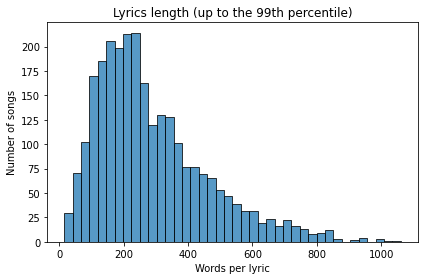

In [ ]:
print(df_sentiment['lyric_word_count'].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
upper_limit = df_sentiment['lyric_word_count'].quantile(0.99)
sns.histplot(
    data=df_sentiment[df_sentiment['lyric_word_count'] <= upper_limit],
    x='lyric_word_count', bins=40,
)
plt.title('Lyrics length (up to the 99th percentile)')
plt.xlabel('Words per lyric')
plt.ylabel('Number of songs')
plt.tight_layout()
plt.show()

### 3.3. Multivariate Analysis 

#### 3.3.1. Sentiment vs. Metadata 

,song_count,mean_sentiment,median_sentiment,positive_share
tag,,,,
pop,1115,0.358047,0.87910,0.681614
rap,772,-0.224702,-0.88545,0.384715
rock,507,0.031031,0.12800,0.506903
rb,124,0.474902,0.97225,0.741935
misc,113,0.306904,0.86250,0.654867
country,69,0.301129,0.81760,0.652174


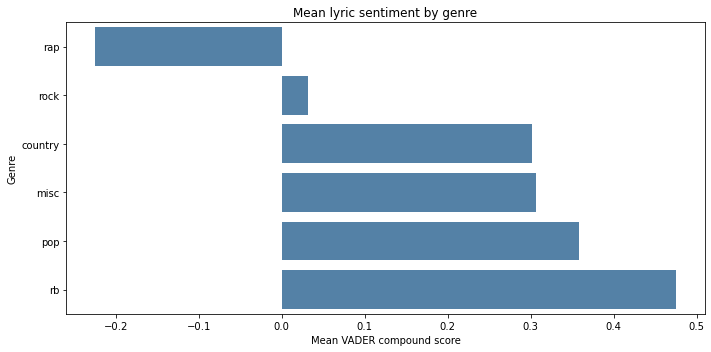

Rows excluded from year analysis: 14


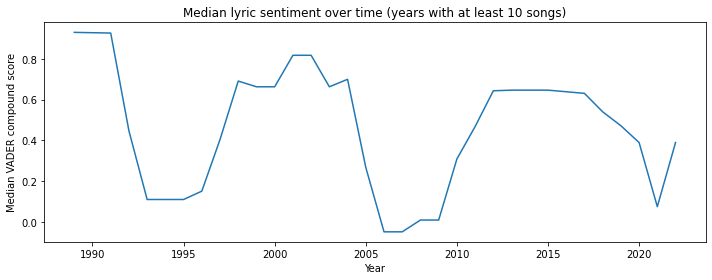

Spearman correlation between views and sentiment: 0.048


,song_count,median_views,mean_sentiment
view_quintile,,,
"(-0.001, 18.0]",542,8.0,0.076807
"(18.0, 51.0]",540,31.0,0.082415
"(51.0, 171.0]",540,93.0,0.166068
"(171.0, 663.2]",538,312.5,0.218485
"(663.2, 479946.0]",540,2209.5,0.115696


In [ ]:
genre_summary = df_sentiment.groupby('tag', dropna=False).agg(
    song_count=('id', 'size'),
    mean_sentiment=('sentiment_compound', 'mean'),
    median_sentiment=('sentiment_compound', 'median'),
    positive_share=('sentiment', lambda values: values.eq('Positive').mean()),
).sort_values('mean_sentiment')
display(genre_summary.sort_values('song_count', ascending=False).head(15))

plt.figure(figsize=(10, 5))
sns.barplot(data=genre_summary.reset_index(), x='mean_sentiment', y='tag', color='steelblue')
plt.title('Mean lyric sentiment by genre')
plt.xlabel('Mean VADER compound score')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

# EDA found implausibly early years; exclude years before 1900 from this trend.
valid_years = df_sentiment[df_sentiment['year'] >= 1900]
print(f"Rows excluded from year analysis: {len(df_sentiment) - len(valid_years):,}")
year_summary = valid_years.groupby('year').agg(
    median_sentiment=('sentiment_compound', 'median'),
    song_count=('id', 'size'),
)
year_summary = year_summary[year_summary['song_count'] >= 10]
year_summary['five_year_median'] = year_summary['median_sentiment'].rolling(5, center=True, min_periods=1).median()
year_summary['five_year_median'].plot(figsize=(10, 4))
plt.title('Median lyric sentiment over time (years with at least 10 songs)')
plt.xlabel('Year')
plt.ylabel('Median VADER compound score')
plt.tight_layout()
plt.show()

view_sentiment_corr = df_sentiment['views'].corr(df_sentiment['sentiment_compound'], method='spearman')
print(f'Spearman correlation between views and sentiment: {view_sentiment_corr:.3f}')
df_sentiment['view_quintile'] = pd.qcut(df_sentiment['views'], q=5, duplicates='drop')
view_summary = df_sentiment.groupby('view_quintile', observed=True).agg(
    song_count=('id', 'size'),
    median_views=('views', 'median'),
    mean_sentiment=('sentiment_compound', 'mean'),
)
display(view_summary)

#### 3.3.2 Word Frequency & Common Terms 

,word,count
0,i'm,6488
1,like,5744
2,know,4413
3,don't,4235
4,just,4160
5,got,3577
6,yeah,3278
7,love,3227
8,it's,3201
9,time,2412


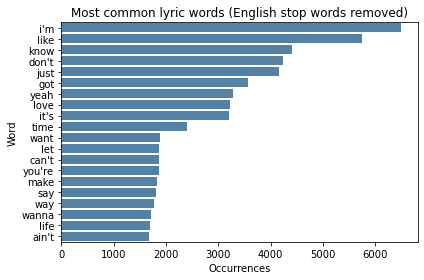

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS) | {'chorus', 'verse', 'bridge', 'intro', 'outro'}
word_counts = Counter()
for lyric in df_sentiment['lyrics']:
    words = re.findall(r"[a-z']+", lyric.lower())
    word_counts.update(word for word in words if len(word) > 2 and word not in stop_words)

top_words = pd.DataFrame(word_counts.most_common(20), columns=['word', 'count'])
display(top_words)
sns.barplot(data=top_words, x='count', y='word', color='steelblue')
plt.title('Most common lyric words (English stop words removed)')
plt.xlabel('Occurrences')
plt.ylabel('Word')
plt.tight_layout()
plt.show()